# ARIMA Product Forecasting — Data Exploration

This notebook performs initial data exploration and EDA on the ProductForecast.xlsx dataset.

## Objectives
1. Load and inspect the data
2. Aggregate data by time period (total Number per month)
3. Visualize time series patterns
4. Check for missing values and outliers
5. Assess trend and seasonality
6. Generate summary statistics

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
import warnings
warnings.filterwarnings('ignore')

# Set plot style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
%matplotlib inline

## 1. Load Data

In [2]:
# Load the Excel file
df_raw = pd.read_excel('../data/ProductForecast.xlsx')

print("Dataset Shape:", df_raw.shape)
print("\nColumn Names:", df_raw.columns.tolist())
print("\nFirst 10 rows:")
df_raw.head(10)

Dataset Shape: (370, 5)

Column Names: ['Time', 'CUSTID', 'ItemCode', 'ITemCategory', 'Number']

First 10 rows:


,Time,CUSTID,ItemCode,ITemCategory,Number
0,2024-11,1016,9745,1,432
1,2024-11,1016,9746,2,420
2,2024-11,1034,9744,1,1176
3,2024-11,1034,9745,1,1056
4,2024-11,1034,9746,1,804
5,2024-12,1016,9745,1,420
6,2024-12,1016,9746,2,372
7,2024-12,1034,9744,1,876
8,2024-12,1034,9745,1,816
9,2024-12,1034,9746,1,504


In [3]:
# Data types and basic info
print("Data Info:")
df_raw.info()

print("\n" + "="*50)
print("Summary Statistics:")
df_raw.describe()

Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 370 entries, 0 to 369
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Time          370 non-null    object
 1   CUSTID        370 non-null    int64 
 2   ItemCode      370 non-null    int64 
 3   ITemCategory  370 non-null    int64 
 4   Number        370 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 14.6+ KB

Summary Statistics:


,CUSTID,ItemCode,ITemCategory,Number
count,370.000000,370.000000,370.000000,370.000000
mean,1025.048649,9745.005405,1.313514,666.227027
std,9.012055,0.816479,0.464549,345.846642
min,1016.000000,9744.000000,1.000000,168.000000
25%,1016.000000,9744.000000,1.000000,396.000000
50%,1034.000000,9745.000000,1.000000,552.000000
75%,1034.000000,9746.000000,2.000000,1020.000000
max,1034.000000,9746.000000,2.000000,1620.000000


In [4]:
# Check unique values
print("Unique Customers:", df_raw['CUSTID'].unique())
print("Unique Item Codes:", df_raw['ItemCode'].unique())
print("Unique Item Categories:", df_raw['ITemCategory'].unique())
print("\nTime Range:", df_raw['Time'].min(), "to", df_raw['Time'].max())
print("Number of Time Periods:", df_raw['Time'].nunique())

Unique Customers: [1016 1034]
Unique Item Codes: [9745 9746 9744]
Unique Item Categories: [1 2]

Time Range: 2024-11 to 2029-12
Number of Time Periods: 62


## 2. Aggregate Data by Time Period

We'll aggregate the `Number` column across all customers and products to create a single time series.

In [5]:
# Aggregate by Time period (sum of Number across all customers/products)
df_ts = df_raw.groupby('Time')['Number'].sum().reset_index()
df_ts.columns = ['Date', 'Total_Number']

# Convert Time to datetime
df_ts['Date'] = pd.to_datetime(df_ts['Date'], format='%Y-%m')

# Set Date as index
df_ts.set_index('Date', inplace=True)

# Set frequency to monthly
df_ts = df_ts.asfreq('MS')  # MS = month start

print("Aggregated Time Series Shape:", df_ts.shape)
print("\nFirst 10 records:")
print(df_ts.head(10))
print("\nLast 10 records:")
print(df_ts.tail(10))

Aggregated Time Series Shape: (62, 1)

First 10 records:
            Total_Number
Date                    
2024-11-01          3888
2024-12-01          2988
2025-01-01          4008
2025-02-01          4368
2025-03-01          4332
2025-04-01          4668
2025-05-01          5148
2025-06-01          4572
2025-07-01          5220
2025-08-01          4536

Last 10 records:
            Total_Number
Date                    
2029-03-01          3720
2029-04-01          3744
2029-05-01          3720
2029-06-01          3720
2029-07-01          3684
2029-08-01          3528
2029-09-01          3528
2029-10-01          3480
2029-11-01          3516
2029-12-01          3468


In [6]:
# Check for missing values
print("Missing Values:")
print(df_ts.isnull().sum())

print("\nBasic Statistics:")
print(df_ts.describe())

Missing Values:
Total_Number    0
dtype: int64

Basic Statistics:
       Total_Number
count     62.000000
mean    3975.870968
std      391.824630
min     2988.000000
25%     3768.000000
50%     3900.000000
75%     4020.000000
max     5220.000000


## 3. Visualize Time Series

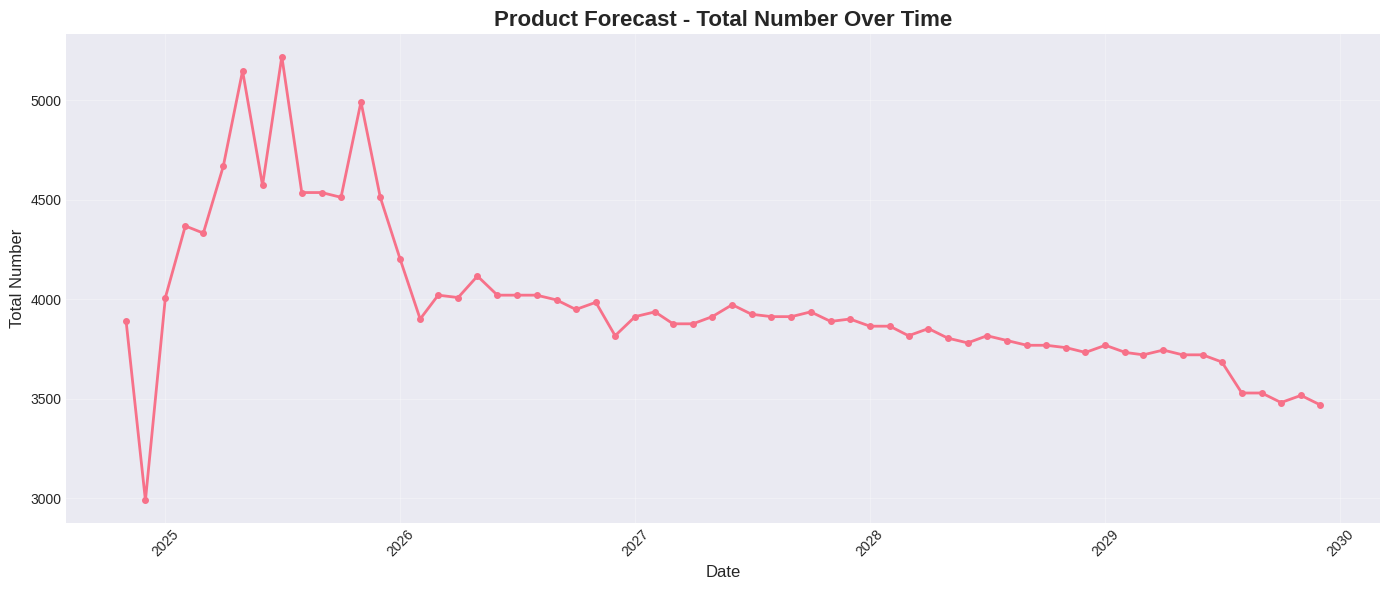

Visualization saved to: outputs/visualizations/01_timeseries_overview.png


In [7]:
# Plot the complete time series
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(df_ts.index, df_ts['Total_Number'], marker='o', linestyle='-', linewidth=2, markersize=4)
ax.set_title('Product Forecast - Total Number Over Time', fontsize=16, fontweight='bold')
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Total Number', fontsize=12)
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../outputs/visualizations/01_timeseries_overview.png', dpi=300, bbox_inches='tight')
plt.show()

print("Visualization saved to: outputs/visualizations/01_timeseries_overview.png")

## 4. Decomposition Analysis

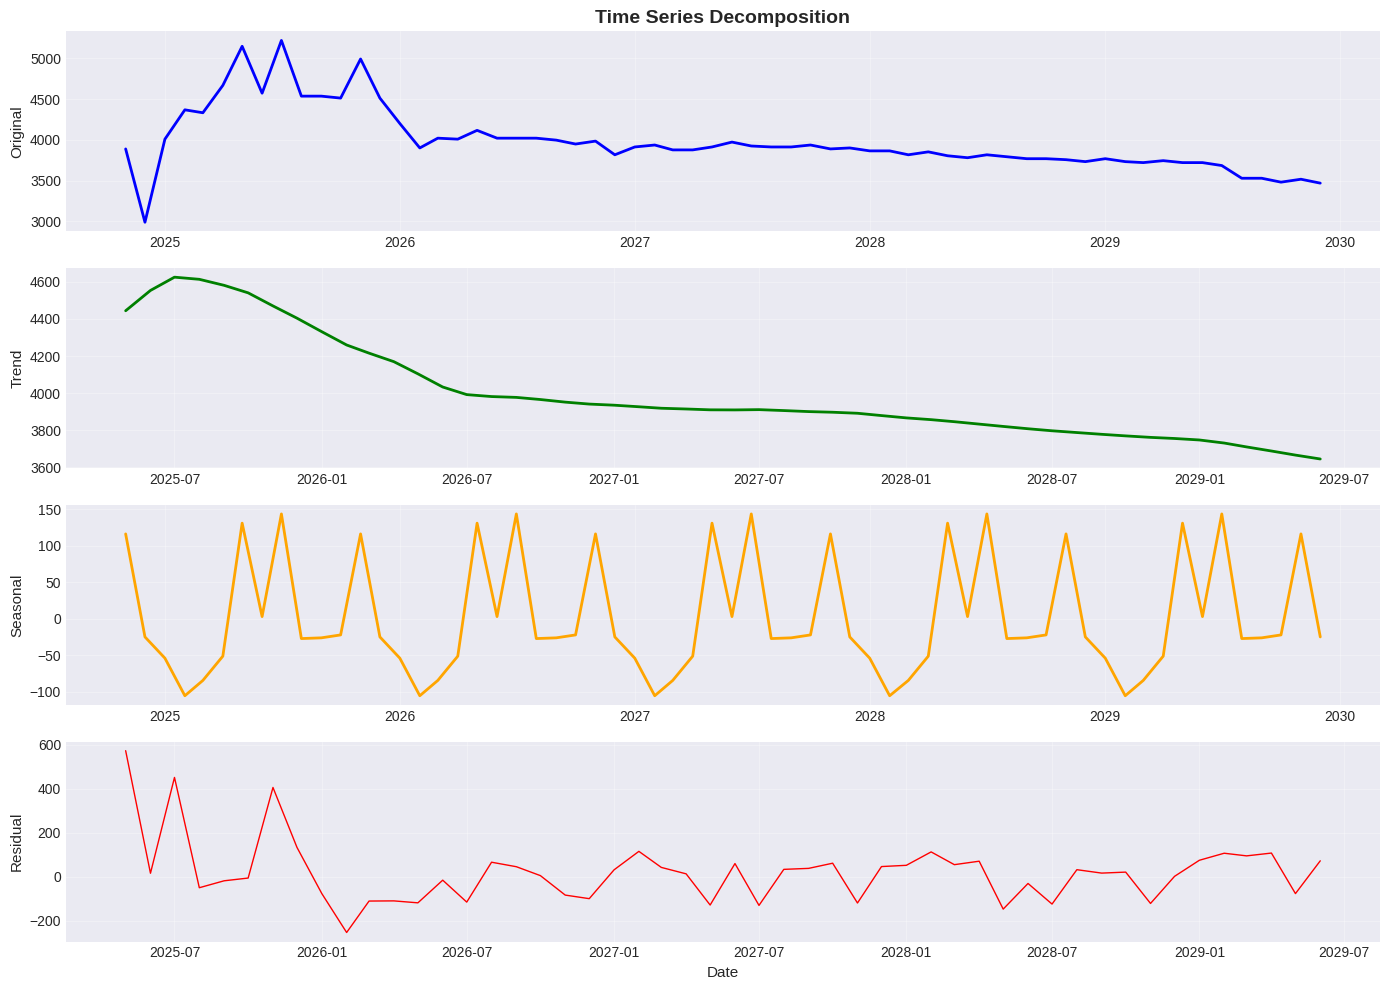

Decomposition plot saved to: outputs/visualizations/02_decomposition.png


In [8]:
# Perform seasonal decomposition
# Using additive model (can try multiplicative if needed)
decomposition = seasonal_decompose(df_ts['Total_Number'], model='additive', period=12)

# Plot decomposition
fig, axes = plt.subplots(4, 1, figsize=(14, 10))

# Original
axes[0].plot(df_ts.index, df_ts['Total_Number'], color='blue', linewidth=2)
axes[0].set_ylabel('Original', fontsize=11)
axes[0].set_title('Time Series Decomposition', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Trend
axes[1].plot(decomposition.trend.index, decomposition.trend, color='green', linewidth=2)
axes[1].set_ylabel('Trend', fontsize=11)
axes[1].grid(True, alpha=0.3)

# Seasonal
axes[2].plot(decomposition.seasonal.index, decomposition.seasonal, color='orange', linewidth=2)
axes[2].set_ylabel('Seasonal', fontsize=11)
axes[2].grid(True, alpha=0.3)

# Residual
axes[3].plot(decomposition.resid.index, decomposition.resid, color='red', linewidth=1)
axes[3].set_ylabel('Residual', fontsize=11)
axes[3].set_xlabel('Date', fontsize=11)
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../outputs/visualizations/02_decomposition.png', dpi=300, bbox_inches='tight')
plt.show()

print("Decomposition plot saved to: outputs/visualizations/02_decomposition.png")

## 5. Distribution Analysis

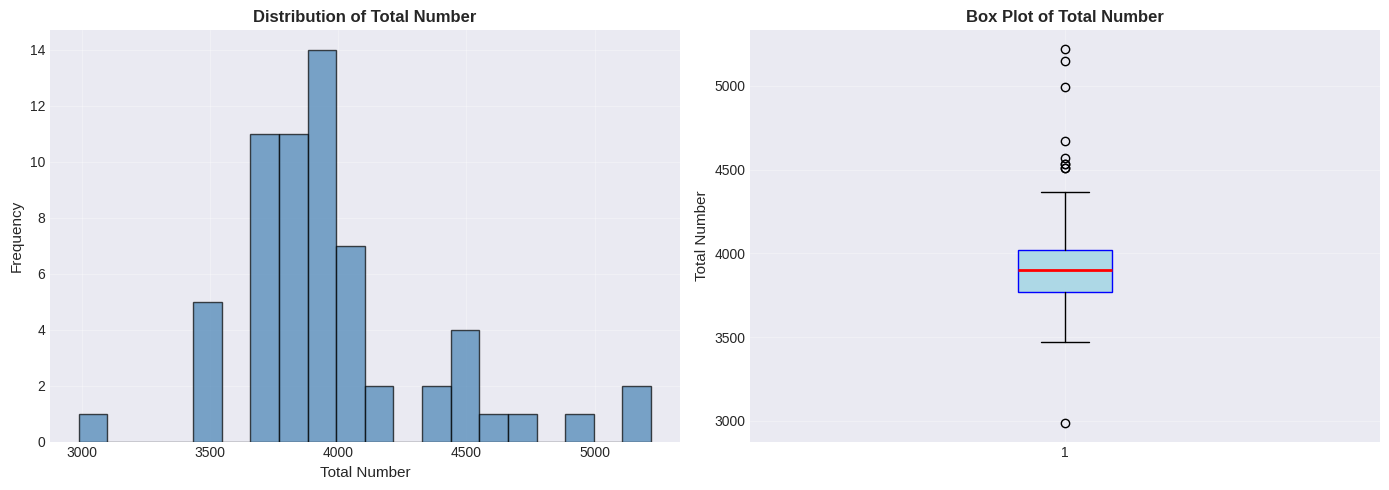

In [9]:
# Plot distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df_ts['Total_Number'], bins=20, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].set_title('Distribution of Total Number', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Total Number', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].grid(True, alpha=0.3)

# Box plot
axes[1].boxplot(df_ts['Total_Number'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='blue'),
                medianprops=dict(color='red', linewidth=2))
axes[1].set_title('Box Plot of Total Number', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Total Number', fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Rolling Statistics

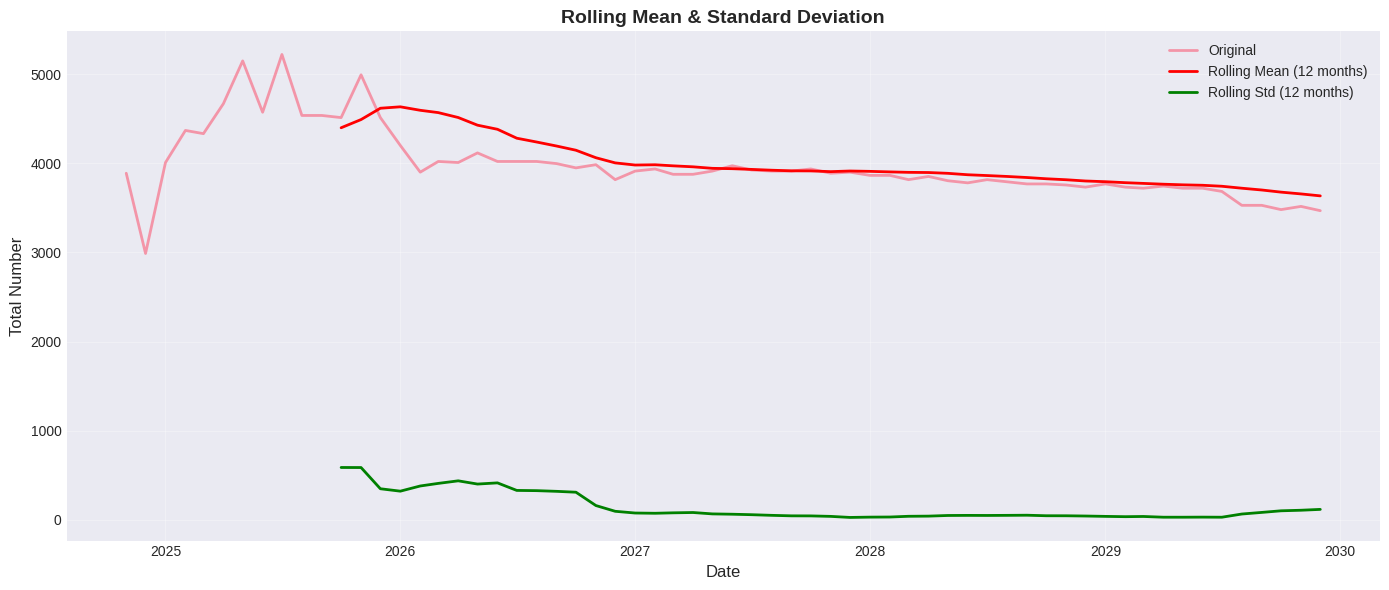

In [10]:
# Calculate rolling mean and std
rolling_mean = df_ts['Total_Number'].rolling(window=12).mean()
rolling_std = df_ts['Total_Number'].rolling(window=12).std()

# Plot
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(df_ts.index, df_ts['Total_Number'], label='Original', linewidth=2, alpha=0.7)
ax.plot(rolling_mean.index, rolling_mean, label='Rolling Mean (12 months)', linewidth=2, color='red')
ax.plot(rolling_std.index, rolling_std, label='Rolling Std (12 months)', linewidth=2, color='green')
ax.set_title('Rolling Mean & Standard Deviation', fontsize=14, fontweight='bold')
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Total Number', fontsize=12)
ax.legend(loc='best')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Key Observations

Based on the exploratory analysis:

In [11]:
print("=" * 60)
print("KEY OBSERVATIONS FROM EDA")
print("=" * 60)

print(f"\n1. Time Period: {df_ts.index.min().strftime('%Y-%m')} to {df_ts.index.max().strftime('%Y-%m')}")
print(f"   Total Months: {len(df_ts)}")

print(f"\n2. Value Range:")
print(f"   Minimum: {df_ts['Total_Number'].min()}")
print(f"   Maximum: {df_ts['Total_Number'].max()}")
print(f"   Mean: {df_ts['Total_Number'].mean():.2f}")
print(f"   Median: {df_ts['Total_Number'].median():.2f}")
print(f"   Std Dev: {df_ts['Total_Number'].std():.2f}")

print(f"\n3. Missing Values: {df_ts['Total_Number'].isnull().sum()}")

# Check for trend
trend_direction = "Increasing" if df_ts['Total_Number'].iloc[-12:].mean() > df_ts['Total_Number'].iloc[:12].mean() else "Decreasing"
print(f"\n4. Overall Trend: {trend_direction}")

print("\n5. Next Steps:")
print("   - Perform stationarity test (ADF)")
print("   - Apply differencing if needed")
print("   - Determine ARIMA parameters")
print("   - Build and validate model")

print("\n" + "="*60)

KEY OBSERVATIONS FROM EDA

1. Time Period: 2024-11 to 2029-12
   Total Months: 62

2. Value Range:
   Minimum: 2988
   Maximum: 5220
   Mean: 3975.87
   Median: 3900.00
   Std Dev: 391.82

3. Missing Values: 0

4. Overall Trend: Decreasing

5. Next Steps:
   - Perform stationarity test (ADF)
   - Apply differencing if needed
   - Determine ARIMA parameters
   - Build and validate model



## 8. Save Cleaned Data

In [12]:
# Save the aggregated time series for use in modeling notebook
df_ts.to_csv('../outputs/cleaned_timeseries.csv')
print("Cleaned time series saved to: outputs/cleaned_timeseries.csv")
print(f"\nShape: {df_ts.shape}")
print(f"Date Range: {df_ts.index.min()} to {df_ts.index.max()}")

Cleaned time series saved to: outputs/cleaned_timeseries.csv

Shape: (62, 1)
Date Range: 2024-11-01 00:00:00 to 2029-12-01 00:00:00
